# TC3-43 – Analisar distribuição do target

**Responsável:** Mauricio Cruz

**Sprint:** Fase 3

**Jira:** TC3-43

## Objetivo

Avaliar a distribuição da variável-alvo alfabetizado, identificando as classes existentes, calculando suas quantidades absolutas e proporções percentuais, verificando a presença de desbalanceamento e representando os resultados por meio de gráfico. Documentar as conclusões e os possíveis impactos na escolha das métricas e na avaliação dos modelos de Machine Learning.


## Inicialização independente

Esta célula reproduz a configuração compartilhada do notebook principal. Ela prepara ambiente, caminhos e funções comuns sem alterar a lógica canônica desta etapa.


In [1]:
# =============================================================================
# CONFIGURAÇÕES PARA RODAR O NOTEBOOK
# Execute esta célula primeiro. Esta política não altera a metodologia do fluxo.
# =============================================================================
import os
import sys
import gc
import ctypes
import polars as pl
from datetime import datetime, timezone

# Opções do usuário
PERFIL_RECURSOS = "auto"       # auto | baixo | medio | normal | alto
LIMITE_RAM_PERCENTUAL = None    # None = automático; ou inteiro entre 50 e 90
MAX_THREADS = None              # None = automático; ou inteiro >= 1
USAR_GPU = os.getenv("TC3_USAR_GPU", "1").strip().lower() in {"1", "true", "sim", "yes"}                 # requer WSL2 + RAPIDS/cuML + kernel tc3-gpu

REUTILIZAR_ARTEFATOS = False  # False reconstrói; True aceita caches válidos
SALVAR_ARTEFATOS = True       # False usa somente área temporária da sessão


# Protocolo metodologico compartilhado por todas as fases e modelos.
SEED_GLOBAL = 42
EXECUTAR_SHAP = os.getenv("TC3_EXECUTAR_SHAP", "0").strip().lower() in {"1", "true", "sim", "yes"}
AMOSTRA_SHAP = max(20, int(os.getenv("TC3_AMOSTRA_SHAP", "100")))
AMOSTRA_BACKGROUND_SHAP = max(20, int(os.getenv("TC3_BACKGROUND_SHAP", "50")))
CHAVE_GRUPO_GLOBAL = "chave_escola_ano"
N_SPLITS_CV_GLOBAL = 3
N_ITER_BUSCA_GLOBAL = 10
LIMIAR_CLASSIFICACAO_GLOBAL = 0.50
REPETICOES_PERMUTACAO_GLOBAL = 5
REPETICOES_BOOTSTRAP_GLOBAL = 200

N_JOBS_MODELAGEM_GLOBAL = 1
N_SPLITS_HOLDOUT_GLOBAL = 1
SCORING_PRINCIPAL_GLOBAL = "roc_auc"
VERBOSE_BUSCA_GLOBAL = 2
ERRO_BUSCA_GLOBAL = "raise"
RETORNAR_SCORE_TREINO_GLOBAL = True

# Contrato comum de pre-processamento dos modelos.
IMPUTACAO_NUMERICA_GLOBAL = "median"
IMPUTACAO_CATEGORICA_GLOBAL = "most_frequent"
ONE_HOT_DESCONHECIDO_GLOBAL = "ignore"
ONE_HOT_SPARSO_GLOBAL = False  # matriz densa: evita fallback dos modelos para CPU
SPARSE_THRESHOLD_GLOBAL = 0.0
ESCALONADOR_CENTRALIZAR_GLOBAL = False


# Percentuais de amostragem (0 < valor <= 1). Alterar aqui afeta todo o notebook.
# O teste final permanece integral (100%); as amostras menores servem apenas ao
# desenvolvimento, comparacao de modelos e interpretabilidade.
FRACOES_AMOSTRAGEM = {
    "eda_correlacao": 0.05,
    "validacao_preparacao": 0.02,
    "fase5_modelos": 0.10,
    "fase5_knn": 0.02,  # KNN tem custo de memoria e predicao maior.
    "fase6_desenvolvimento": 0.12,
    "fase6_validacao_interna": 0.25,
    "fase7_desenvolvimento": 1.00,
    "fase7_teste": 1.00,
    "interpretacao": 0.035,
    "bootstrap": 0.17,
}

for _nome, _fracao in FRACOES_AMOSTRAGEM.items():
    if not 0 < _fracao <= 1:
        raise ValueError(f"Fracao invalida em FRACOES_AMOSTRAGEM[{_nome!r}]: {_fracao}")


def tamanho_por_fracao(total, fracao):
    """Converte uma proporcao em quantidade reproduzivel, sem exceder o total."""
    if total < 1:
        raise ValueError("Nao e possivel amostrar uma particao vazia.")
    return min(total, max(1, round(total * fracao)))


def materializar_split_percentual(dados, contrato, nome_split, fracao, seed, materializador):
    """Materializa uma fracao de um split e informa claramente o universo usado."""
    import polars as pl

    coluna_split = contrato["controle_split"]
    total = (
        dados.filter(pl.col(coluna_split) == nome_split)
        .select(pl.len().alias("total"))
        .collect()
        .item()
    )
    quantidade = tamanho_por_fracao(total, fracao)
    X, y = materializador(dados, contrato, nome_split, limit=quantidade, seed=seed)
    print(f"{nome_split}: {quantidade:,}/{total:,} registros ({fracao:.1%})")
    return X, y


def _estado_memoria_sistema():
    """Retorna RAM total e disponível em bytes."""
    valores = {}
    try:
        with open("/proc/meminfo", encoding="utf-8") as arquivo:
            for linha in arquivo:
                chave, valor = linha.split(":", 1)
                valores[chave] = int(valor.strip().split()[0]) * 1024
        return valores["MemTotal"], valores.get("MemAvailable", valores.get("MemFree", 0))
    except (OSError, KeyError, ValueError):
        try:
            return (
                os.sysconf("SC_PHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
                os.sysconf("SC_AVPHYS_PAGES") * os.sysconf("SC_PAGE_SIZE"),
            )
        except (AttributeError, OSError, ValueError):
            return None, None


RAM_TOTAL_BYTES, RAM_DISPONIVEL_BYTES = _estado_memoria_sistema()
RAM_TOTAL_GB = RAM_TOTAL_BYTES / 1024**3 if RAM_TOTAL_BYTES else 0.0
CPUS_LOGICAS = os.cpu_count() or 1

if RAM_TOTAL_GB and RAM_TOTAL_GB <= 4.5:
    _perfil_detectado = "baixo"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 8.5:
    _perfil_detectado = "medio"
elif RAM_TOTAL_GB and RAM_TOTAL_GB <= 16.5:
    _perfil_detectado = "normal"
else:
    _perfil_detectado = "alto"

_perfis = {
    "baixo": (60, 1),
    "medio": (70, min(2, CPUS_LOGICAS)),
    "normal": (75, min(4, CPUS_LOGICAS)),
    "alto": (80, min(8, max(1, CPUS_LOGICAS // 2))),
}
PERFIL_ATIVO = _perfil_detectado if PERFIL_RECURSOS == "auto" else PERFIL_RECURSOS.lower()
if PERFIL_ATIVO not in _perfis:
    raise ValueError("PERFIL_RECURSOS deve ser auto, baixo, medio, normal ou alto.")

_limite_perfil, _threads_perfil = _perfis[PERFIL_ATIVO]
LIMITE_RAM_ATIVO = _limite_perfil if LIMITE_RAM_PERCENTUAL is None else int(LIMITE_RAM_PERCENTUAL)
THREADS_MAXIMAS = _threads_perfil if MAX_THREADS is None else int(MAX_THREADS)
if not 50 <= LIMITE_RAM_ATIVO <= 90:
    raise ValueError("LIMITE_RAM_PERCENTUAL deve ficar entre 50 e 90.")
if THREADS_MAXIMAS < 1:
    raise ValueError("MAX_THREADS deve ser pelo menos 1.")
THREADS_MAXIMAS = min(THREADS_MAXIMAS, CPUS_LOGICAS)

# Definido antes de NumPy, Polars, scikit-learn e cuML serem importados.
for _variavel, _valor in {
    "OMP_NUM_THREADS": str(THREADS_MAXIMAS),
    "OPENBLAS_NUM_THREADS": str(THREADS_MAXIMAS),
    "MKL_NUM_THREADS": str(THREADS_MAXIMAS),
    "NUMEXPR_NUM_THREADS": str(THREADS_MAXIMAS),
    "VECLIB_MAXIMUM_THREADS": str(THREADS_MAXIMAS),
    "POLARS_MAX_THREADS": str(THREADS_MAXIMAS),
    "MALLOC_ARENA_MAX": "2",
}.items():
    os.environ[_variavel] = _valor

HISTORICO_RECURSOS = []
_estado_recursos = {"nivel": None, "threads": None, "contexto_threads": None}


def _aplicar_threads(limite):
    """Limita pools BLAS/OpenMP já carregados; Polars usa o limite inicial."""
    limite = max(1, min(int(limite), THREADS_MAXIMAS))
    if _estado_recursos["threads"] == limite:
        return
    anterior = _estado_recursos.get("contexto_threads")
    if anterior is not None:
        try:
            anterior.__exit__(None, None, None)
        except Exception:
            pass
    try:
        from threadpoolctl import threadpool_limits
        contexto = threadpool_limits(limits=limite)
        contexto.__enter__()
    except Exception:
        contexto = None
    _estado_recursos["contexto_threads"] = contexto
    _estado_recursos["threads"] = limite


def _liberar_memoria_global(agressiva=False):
    """Libera caches transitórios sem apagar variáveis usadas pelo fluxo."""
    shell = get_ipython()
    if shell is not None:
        for nome in ("_", "__", "___"):
            shell.user_ns[nome] = None
    gc.collect()
    modulo_cupy = sys.modules.get("cupy")
    if modulo_cupy is not None:
        try:
            modulo_cupy.get_default_memory_pool().free_all_blocks()
            modulo_cupy.get_default_pinned_memory_pool().free_all_blocks()
        except Exception:
            pass
    if agressiva:
        modulo_plt = sys.modules.get("matplotlib.pyplot")
        if modulo_plt is not None:
            try:
                modulo_plt.close("all")
            except Exception:
                pass
        try:
            ctypes.CDLL("libc.so.6").malloc_trim(0)
        except (OSError, AttributeError):
            pass


def _gerenciar_recursos(*_args, **_kwargs):
    """Reduz paralelismo progressivamente e nunca interrompe uma célula."""
    total, disponivel = _estado_memoria_sistema()
    if not total:
        return
    uso = 100.0 * (total - disponivel) / total
    margem = LIMITE_RAM_ATIVO - uso
    if margem > 15:
        nivel, threads, limpar = "normal", THREADS_MAXIMAS, False
    elif margem > 7:
        nivel, threads, limpar = "moderado", max(1, THREADS_MAXIMAS // 2), True
    else:
        nivel, threads, limpar = "conservador", 1, True

    _aplicar_threads(threads)
    if limpar:
        _liberar_memoria_global(agressiva=margem <= 0)

    if nivel != _estado_recursos["nivel"]:
        registro = {
            "instante_utc": datetime.now(timezone.utc).isoformat(),
            "nivel": nivel,
            "threads": threads,
            "ram_usada_percentual": round(uso, 1),
            "ram_disponivel_gb": round(disponivel / 1024**3, 2),
        }
        HISTORICO_RECURSOS.append(registro)
        print(
            f"[recursos] nível={nivel}; threads={threads}; "
            f"RAM usada={uso:.1f}%; livre={disponivel / 1024**3:.1f} GB."
        )
        _estado_recursos["nivel"] = nivel


ipython = get_ipython()
if ipython is not None:
    # Impede callbacks duplicados ao reexecutar a configuração.
    for _atributo in ("_tc3_memory_guard", "_tc3_resource_guard"):
        _guard_anterior = getattr(ipython, _atributo, None)
        if _guard_anterior is not None:
            for _evento, _funcao in _guard_anterior:
                try:
                    ipython.events.unregister(_evento, _funcao)
                except (ValueError, KeyError):
                    pass
    _callbacks_recursos = [
        ("pre_run_cell", _gerenciar_recursos),
        ("post_run_cell", _gerenciar_recursos),
    ]
    for _evento, _funcao in _callbacks_recursos:
        ipython.events.register(_evento, _funcao)
    ipython._tc3_resource_guard = _callbacks_recursos

_gerenciar_recursos()
print(
    "Configuração automática ativa: "
    f"perfil={PERFIL_ATIVO}; RAM={RAM_TOTAL_GB:.1f} GB; CPUs={CPUS_LOGICAS}; "
    f"limite preventivo={LIMITE_RAM_ATIVO}%; threads máximas={THREADS_MAXIMAS}."
)

# Backend GPU: ativado antes de qualquer importação do scikit-learn.
cuda_conda = os.path.join(sys.prefix, "targets", "x86_64-linux")
if os.path.exists(os.path.join(cuda_conda, "include", "cuda.h")):
    os.environ.setdefault("CUDA_PATH", cuda_conda)
if USAR_GPU:
    try:
        from cuml.accel import install
        install(log_level="info")
        import cupy as cp
        dispositivo = cp.cuda.runtime.getDeviceProperties(0)
        nome_gpu = dispositivo["name"].decode() if isinstance(dispositivo["name"], bytes) else str(dispositivo["name"])
        memoria_gpu_gb = cp.cuda.runtime.memGetInfo()[1] / 1024**3
        BACKEND_ML = f"RAPIDS cuML — {nome_gpu} ({memoria_gpu_gb:.1f} GB de VRAM)"
    except Exception as exc:
        raise RuntimeError("GPU/RAPIDS indisponível. Abra no WSL2 e selecione o kernel tc3-gpu.") from exc
else:
    BACKEND_ML = "scikit-learn CPU"
print("Backend de Machine Learning:", BACKEND_ML)

from pathlib import Path
import hashlib
import json
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

def localizar_raiz(inicio: Path) -> Path:
    for candidato in [inicio, *inicio.parents]:
        if (candidato / "dados").is_dir() and (candidato / "notebooks").is_dir():
            return candidato
    raise FileNotFoundError("Execute este notebook dentro do repositório tech_challenge_3.")

PROJECT_ROOT = localizar_raiz(Path.cwd().resolve())
print("Raiz do projeto:", PROJECT_ROOT)


# Contrato único de diretórios. Fontes sempre são lidas da área imutável.
import tempfile

FONTES_ORIGINAIS_DIR = PROJECT_ROOT / "dados" / "fontes_originais"
_TEMP_BASE = PROJECT_ROOT / ".execucao_temporaria"
_TEMP_BASE.mkdir(parents=True, exist_ok=True)
if SALVAR_ARTEFATOS:
    RAIZ_ARTEFATOS = PROJECT_ROOT
    _DIRETORIO_TEMPORARIO = None
else:
    _DIRETORIO_TEMPORARIO = tempfile.TemporaryDirectory(prefix="tc3_", dir=_TEMP_BASE)
    RAIZ_ARTEFATOS = Path(_DIRETORIO_TEMPORARIO.name)

DADOS_PROCESSADOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_processados"
DADOS_ANALITICOS_DIR = RAIZ_ARTEFATOS / "dados" / "dados_analiticos"
RESULTADOS_DIR = RAIZ_ARTEFATOS / "resultados"
RESULTADOS_FIGURAS_DIR = RESULTADOS_DIR / "figuras"
RESULTADOS_TABELAS_DIR = RESULTADOS_DIR / "tabelas"
RESULTADOS_METRICAS_DIR = RESULTADOS_DIR / "metricas"
RESULTADOS_RELATORIOS_DIR = RESULTADOS_DIR / "relatorios"
MODELOS_DIR = RAIZ_ARTEFATOS / "modelos"

for _diretorio_saida in (
    DADOS_PROCESSADOS_DIR, DADOS_ANALITICOS_DIR, RESULTADOS_FIGURAS_DIR,
    RESULTADOS_TABELAS_DIR, RESULTADOS_METRICAS_DIR,
    RESULTADOS_RELATORIOS_DIR, MODELOS_DIR,
):
    _diretorio_saida.mkdir(parents=True, exist_ok=True)

def deve_recalcular(caminho):
    """True quando o cache deve ser ignorado ou ainda não existe."""
    return not REUTILIZAR_ARTEFATOS or not Path(caminho).exists()


def publicar_parquet_particionado(frame, destino, *, particionar_por):
    """Publica partições sequencialmente e troca o diretório de forma atômica.

    O ``write_parquet(partition_by=...)`` do Polars prepara várias partições em
    paralelo e pode duplicar o pico de RAM de bases já materializadas. Esta
    implementação mantém apenas uma partição adicional em memória por vez.
    """
    import gc
    import shutil

    destino = Path(destino)
    temporario = destino.with_name(destino.name + "__publicacao_tmp")
    anterior = destino.with_name(destino.name + "__publicacao_anterior")
    for caminho in (temporario, anterior):
        if caminho.exists():
            shutil.rmtree(caminho)
    temporario.mkdir(parents=True, exist_ok=True)

    lazy = frame if isinstance(frame, pl.LazyFrame) else frame.lazy()
    schema = lazy.collect_schema()
    if particionar_por not in schema.names():
        raise ValueError(f"Coluna de particionamento ausente: {particionar_por}")

    valores = (
        lazy.select(pl.col(particionar_por).unique())
        .collect(engine="streaming")
        .get_column(particionar_por)
        .to_list()
    )
    valores = sorted(valores, key=lambda valor: (valor is None, str(valor)))
    if not valores:
        raise RuntimeError("Não há valores para particionar a publicação.")

    arquivos_novos = []
    for indice, valor in enumerate(valores):
        valor_hive = "__HIVE_DEFAULT_PARTITION__" if valor is None else str(valor)
        if any(separador in valor_hive for separador in ("/", "\\")):
            raise ValueError(f"Valor de partição inválido: {valor_hive!r}")
        diretorio_particao = temporario / f"{particionar_por}={valor_hive}"
        diretorio_particao.mkdir(parents=True, exist_ok=True)
        arquivo = diretorio_particao / f"part-{indice:05d}.parquet"
        predicado = pl.col(particionar_por).is_null() if valor is None else pl.col(particionar_por) == pl.lit(valor)
        lazy.filter(predicado).sink_parquet(
            arquivo,
            compression="zstd",
            statistics=True,
            row_group_size=100_000,
            mkdir=True,
            engine="streaming",
        )
        if not arquivo.is_file() or arquivo.stat().st_size == 0:
            raise RuntimeError(f"Partição não foi gravada corretamente: {arquivo}")
        arquivos_novos.append(arquivo)
        gc.collect()

    if destino.exists():
        destino.replace(anterior)
    try:
        try:
            temporario.replace(destino)
        except OSError:
            # Volumes Docker montados do Windows podem bloquear rename de diretórios.
            # O fallback copia a publicação pronta e remove a área temporária.
            shutil.copytree(temporario, destino)
            shutil.rmtree(temporario)
    except Exception:
        if destino.exists():
            shutil.rmtree(destino)
        if anterior.exists():
            anterior.replace(destino)
        raise
    if anterior.exists():
        shutil.rmtree(anterior)
    return len(arquivos_novos)


def salvar_figura_eda(figura, nome):
    """Exporta uma figura exploratória sem alterar sua exibição no notebook."""
    destino = RESULTADOS_FIGURAS_DIR / "fluxo_exploratorio" / nome
    destino.parent.mkdir(parents=True, exist_ok=True)
    figura.savefig(destino, dpi=180, bbox_inches="tight")
    return destino

print("Fontes originais:", FONTES_ORIGINAIS_DIR)
print("Destino dos artefatos:", RAIZ_ARTEFATOS)
print("Reutilizar artefatos:", REUTILIZAR_ARTEFATOS, "| Salvar:", SALVAR_ARTEFATOS)

# Imports compartilhados que, no fluxo completo, são carregados por etapas anteriores.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


[recursos] nível=moderado; threads=2; RAM usada=66.1%; livre=5.2 GB.
Configuração automática ativa: perfil=normal; RAM=15.5 GB; CPUs=20; limite preventivo=75%; threads máximas=4.
[cuml.accel] Accelerator installed.
Backend de Machine Learning: RAPIDS cuML — NVIDIA GeForce RTX 3050 6GB Laptop GPU (6.0 GB de VRAM)
Raiz do projeto: /workspace
Fontes originais: /workspace/dados/fontes_originais
Destino dos artefatos: /workspace
Reutilizar artefatos: False | Salvar: True
[recursos] nível=conservador; threads=1; RAM usada=68.5%; livre=4.9 GB.


In [2]:
import polars as pl
from pathlib import Path
import matplotlib.pyplot as plt


### Carregamento dos dados (partitioned by sigla_uf)


In [3]:
# Raiz e diretórios ativos herdados da configuração central.
BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"

# Leitura lazy com particionamento por UF
df = pl.scan_parquet(
    str(BASE_PATH / "sigla_uf=*" / "*.parquet"),
    hive_partitioning=True
)

### Avaliação da distribuição da variável-alvo alfabetizado


In [4]:
# Contagem absoluta e proporção
distribuicao = (
    df
    .select("alfabetizado")
    .group_by("alfabetizado")
    .agg(pl.len().alias("quantidade"))
    .with_columns(
        (pl.col("quantidade") / pl.col("quantidade").sum() * 100)
        .round(2)
        .alias("proporcao_pct")
    )
    .sort("quantidade", descending=True)
    .collect()
)

print("=== Distribuição da variável-alvo 'alfabetizado' ===")
print(distribuicao)

=== Distribuição da variável-alvo 'alfabetizado' ===
shape: (2, 3)
┌──────────────┬────────────┬───────────────┐
│ alfabetizado ┆ quantidade ┆ proporcao_pct │
│ ---          ┆ ---        ┆ ---           │
│ i32          ┆ u32        ┆ f64           │
╞══════════════╪════════════╪═══════════════╡
│ 1            ┆ 1984546    ┆ 51.31         │
│ 0            ┆ 1883453    ┆ 48.69         │
└──────────────┴────────────┴───────────────┘


In [5]:
from pathlib import Path

BASE_PATH = DADOS_PROCESSADOS_DIR / "consolidado" / "base_alunos_municipios_por_uf"

print("Diretório:", BASE_PATH)
print("Existe:", BASE_PATH.exists())

if BASE_PATH.exists():
    arquivos = sorted(BASE_PATH.rglob("*.parquet"))
    print(f"Arquivos Parquet encontrados: {len(arquivos)}")

    for arquivo in arquivos[:20]:
        print(arquivo.relative_to(BASE_PATH))

Diretório: /workspace/dados/dados_processados/consolidado/base_alunos_municipios_por_uf
Existe: True
Arquivos Parquet encontrados: 26
sigla_uf=AC/part-00000.parquet
sigla_uf=AL/part-00001.parquet
sigla_uf=AM/part-00002.parquet
sigla_uf=AP/part-00003.parquet
sigla_uf=BA/part-00004.parquet
sigla_uf=CE/part-00005.parquet
sigla_uf=DF/part-00006.parquet
sigla_uf=ES/part-00007.parquet
sigla_uf=GO/part-00008.parquet
sigla_uf=MA/part-00009.parquet
sigla_uf=MG/part-00010.parquet
sigla_uf=MS/part-00011.parquet
sigla_uf=MT/part-00012.parquet
sigla_uf=PA/part-00013.parquet
sigla_uf=PB/part-00014.parquet
sigla_uf=PE/part-00015.parquet
sigla_uf=PI/part-00016.parquet
sigla_uf=PR/part-00017.parquet
sigla_uf=RJ/part-00018.parquet
sigla_uf=RN/part-00019.parquet


### Visualização


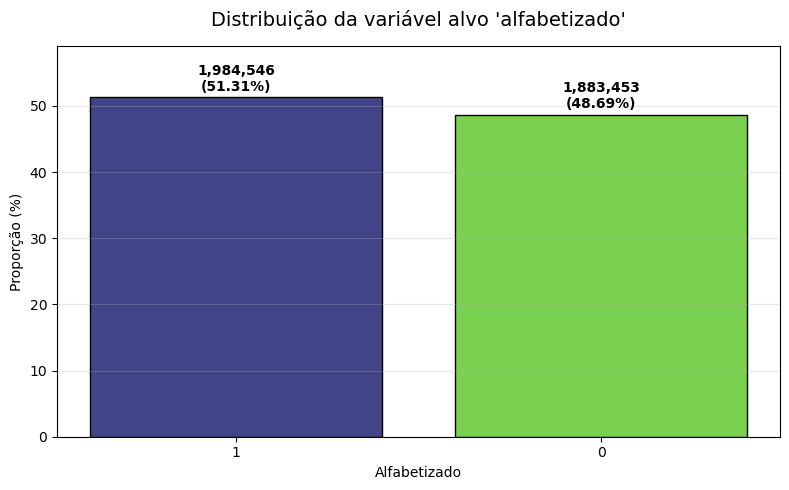

In [6]:
df_plot = distribuicao
classes = df_plot["alfabetizado"].cast(pl.String).to_list()
percentuais = df_plot["proporcao_pct"].to_numpy()
quantidades = df_plot["quantidade"].to_numpy()
plt.figure(figsize=(8, 5)); barras = plt.bar(classes, percentuais, color=plt.cm.viridis(np.linspace(0.2, 0.8, len(classes))), edgecolor="black")
for barra, quantidade, percentual in zip(barras, quantidades, percentuais):
    plt.text(barra.get_x()+barra.get_width()/2, percentual+0.5, f"{int(quantidade):,}\n({percentual}%)", ha="center", va="bottom", fontweight="bold")
plt.title("Distribuição da variável alvo 'alfabetizado'", fontsize=14, pad=15); plt.xlabel("Alfabetizado"); plt.ylabel("Proporção (%)")
plt.ylim(0, float(percentuais.max())*1.15); plt.grid(axis="y", alpha=0.3); plt.tight_layout(); salvar_figura_eda(plt.gcf(), "136_visualizacao_01.png"); plt.show()


### Diagnóstico de desbalanceamento


In [7]:
# Razão entre a classe majoritária e a minoritária
qtd = distribuicao["quantidade"].to_list()
labels = distribuicao["alfabetizado"].to_list()

majoritaria = max(qtd)
minoritaria = min(qtd)
razao = majoritaria / minoritaria if minoritaria > 0 else float("inf")

print("\n=== Diagnóstico de Desbalanceamento ===")
print(f"Classe majoritária : {labels[qtd.index(majoritaria)]} → {majoritaria:,} ({distribuicao.filter(pl.col('quantidade') == majoritaria)['proporcao_pct'][0]}%)")
print(f"Classe minoritária : {labels[qtd.index(minoritaria)]} → {minoritaria:,} ({distribuicao.filter(pl.col('quantidade') == minoritaria)['proporcao_pct'][0]}%)")
print(f"Razão de desbalanceamento: {razao:.2f}:1")



=== Diagnóstico de Desbalanceamento ===
Classe majoritária : 1 → 1,984,546 (51.31%)
Classe minoritária : 0 → 1,883,453 (48.69%)
Razão de desbalanceamento: 1.05:1


### Verificar missing values no target


In [8]:
nulls_target = (
    df
    .select(
        pl.col("alfabetizado").null_count().alias("nulos"),
        pl.len().alias("total")
    )
    .with_columns(
        (pl.col("nulos") / pl.col("total") * 100).round(4).alias("pct_nulos")
    )
    .collect()
)

print(nulls_target)


shape: (1, 3)
┌───────┬─────────┬───────────┐
│ nulos ┆ total   ┆ pct_nulos │
│ ---   ┆ ---     ┆ ---       │
│ u32   ┆ u32     ┆ f64       │
╞═══════╪═════════╪═══════════╡
│ 0     ┆ 3867999 ┆ 0.0       │
└───────┴─────────┴───────────┘


### Distribuição do target por UF


In [9]:
dist_por_uf = (
    df
    .group_by("sigla_uf", "alfabetizado")
    .agg(pl.len().alias("qtd"))
    .with_columns(
        (pl.col("qtd") / pl.col("qtd").sum().over("sigla_uf") * 100)
        .round(2)
        .alias("pct")
    )
    .sort("sigla_uf", "alfabetizado")
    .collect()
)

print(dist_por_uf)

# Pivot para ficar mais legível
dist_pivot = (
    dist_por_uf
    .pivot(index="sigla_uf", on="alfabetizado", values="pct")
    .sort("sigla_uf")
)
print(dist_pivot)


shape: (52, 4)
┌──────────┬──────────────┬────────┬───────┐
│ sigla_uf ┆ alfabetizado ┆ qtd    ┆ pct   │
│ ---      ┆ ---          ┆ ---    ┆ ---   │
│ str      ┆ i32          ┆ u32    ┆ f64   │
╞══════════╪══════════════╪════════╪═══════╡
│ AC       ┆ 0            ┆ 7344   ┆ 58.03 │
│ AC       ┆ 1            ┆ 5311   ┆ 41.97 │
│ AL       ┆ 0            ┆ 39133  ┆ 56.57 │
│ AL       ┆ 1            ┆ 30038  ┆ 43.43 │
│ AM       ┆ 0            ┆ 72843  ┆ 59.87 │
│ …        ┆ …            ┆ …      ┆ …     │
│ SE       ┆ 1            ┆ 12697  ┆ 33.36 │
│ SP       ┆ 0            ┆ 212195 ┆ 47.82 │
│ SP       ┆ 1            ┆ 231582 ┆ 52.18 │
│ TO       ┆ 0            ┆ 24024  ┆ 60.34 │
│ TO       ┆ 1            ┆ 15793  ┆ 39.66 │
└──────────┴──────────────┴────────┴───────┘
shape: (26, 3)
┌──────────┬───────┬───────┐
│ sigla_uf ┆ 0     ┆ 1     │
│ ---      ┆ ---   ┆ ---   │
│ str      ┆ f64   ┆ f64   │
╞══════════╪═══════╪═══════╡
│ AC       ┆ 58.03 ┆ 41.97 │
│ AL       ┆ 56.57 ┆ 43.43 │
│ 

### Verifica se existe alguma UF muito desbalanceada


In [10]:
# Diferença absoluta entre as classes por UF
desbal_uf = (
    dist_por_uf
    .pivot(index="sigla_uf", on="alfabetizado", values="pct")
    .with_columns(
        (pl.col("1") - pl.col("0")).abs().alias("diff_abs")
    )
    .sort("diff_abs", descending=True)
)

print(desbal_uf)


shape: (26, 4)
┌──────────┬───────┬───────┬──────────┐
│ sigla_uf ┆ 0     ┆ 1     ┆ diff_abs │
│ ---      ┆ ---   ┆ ---   ┆ ---      │
│ str      ┆ f64   ┆ f64   ┆ f64      │
╞══════════╪═══════╪═══════╪══════════╡
│ CE       ┆ 17.89 ┆ 82.11 ┆ 64.22    │
│ RN       ┆ 69.58 ┆ 30.42 ┆ 39.16    │
│ BA       ┆ 68.06 ┆ 31.94 ┆ 36.12    │
│ SE       ┆ 66.64 ┆ 33.36 ┆ 33.28    │
│ ES       ┆ 37.43 ┆ 62.57 ┆ 25.14    │
│ …        ┆ …     ┆ …     ┆ …        │
│ MA       ┆ 47.36 ┆ 52.64 ┆ 5.28     │
│ DF       ┆ 52.56 ┆ 47.44 ┆ 5.12     │
│ PB       ┆ 52.39 ┆ 47.61 ┆ 4.78     │
│ SP       ┆ 47.82 ┆ 52.18 ┆ 4.36     │
│ MT       ┆ 48.82 ┆ 51.18 ┆ 2.36     │
└──────────┴───────┴───────┴──────────┘


### Desbalanceamento por UF (gráfico)


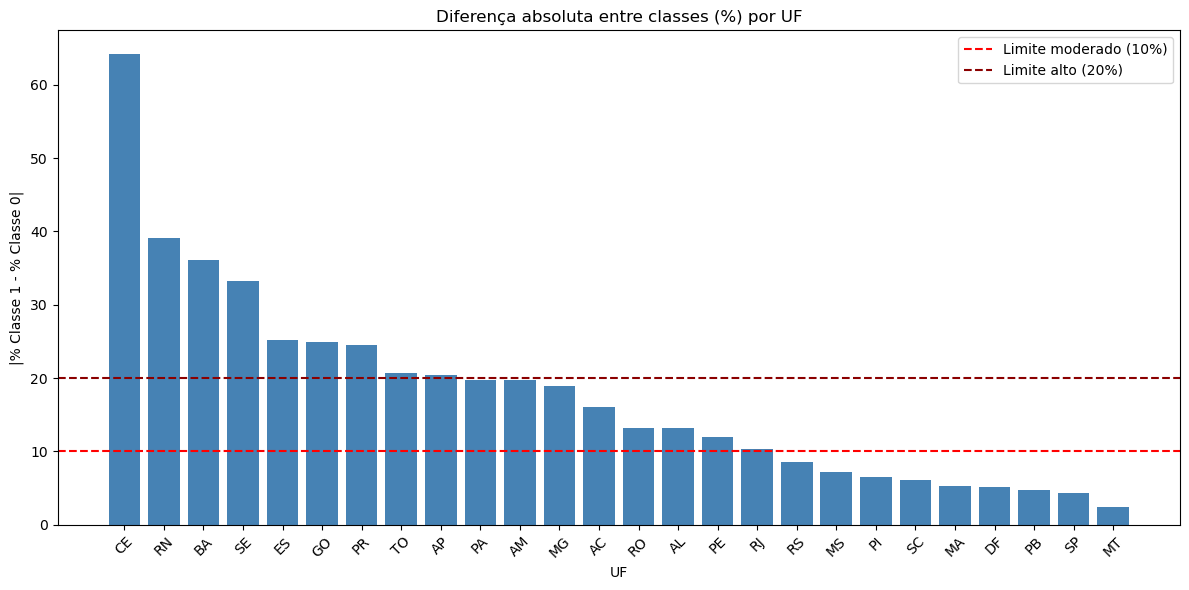

In [11]:
desbal_plot = desbal_uf.sort("diff_abs", descending=True)
plt.figure(figsize=(12, 6)); plt.bar(desbal_plot["sigla_uf"].to_list(), desbal_plot["diff_abs"].to_numpy(), color=plt.cm.rocket(np.linspace(0.1,0.9,desbal_plot.height)) if hasattr(plt.cm,"rocket") else "steelblue")
plt.axhline(10,color="red",linestyle="--",label="Limite moderado (10%)"); plt.axhline(20,color="darkred",linestyle="--",label="Limite alto (20%)")
plt.title("Diferença absoluta entre classes (%) por UF"); plt.xlabel("UF"); plt.ylabel("|% Classe 1 - % Classe 0|"); plt.xticks(rotation=45); plt.legend(); plt.tight_layout(); salvar_figura_eda(plt.gcf(), "146_desbalanceamento_por_uf_grafico_01.png"); plt.show()


### Volume de alunos por UF

Para ver se os estados desbalanceados têm peso grande


In [12]:
volume_uf = (
    df
    .group_by("sigla_uf")
    .agg(pl.len().alias("total_alunos"))
    .with_columns(
        (pl.col("total_alunos") / pl.col("total_alunos").sum() * 100).round(2).alias("pct_total")
    )
    .sort("total_alunos", descending=True)
    .collect()
)

print(volume_uf)


shape: (26, 3)
┌──────────┬──────────────┬───────────┐
│ sigla_uf ┆ total_alunos ┆ pct_total │
│ ---      ┆ ---          ┆ ---       │
│ str      ┆ u32          ┆ f64       │
╞══════════╪══════════════╪═══════════╡
│ SP       ┆ 443777       ┆ 11.47     │
│ MG       ┆ 413557       ┆ 10.69     │
│ RJ       ┆ 311198       ┆ 8.05      │
│ PR       ┆ 277446       ┆ 7.17      │
│ BA       ┆ 253300       ┆ 6.55      │
│ …        ┆ …            ┆ …         │
│ TO       ┆ 39817        ┆ 1.03      │
│ SE       ┆ 38058        ┆ 0.98      │
│ DF       ┆ 27698        ┆ 0.72      │
│ AP       ┆ 24929        ┆ 0.64      │
│ AC       ┆ 12655        ┆ 0.33      │
└──────────┴──────────────┴───────────┘


### Análise de heterogeneidade geográfica do target

- O target está globalmente balanceado (51,3% vs 48,7%).
- Entretanto, existe forte variação entre UFs:
  - Ceará apresenta o maior desbalanceamento (≈64 pontos percentuais a favor da classe 1).
  - Rio Grande do Norte, Bahia e Sergipe também mostram desbalanceamento relevante (>30 pp).
  - São Paulo, Minas Gerais e Mato Grosso estão entre os mais equilibrados.

- Estados com maior volume de alunos (SP, MG, RJ) tendem a ser mais balanceados.
- Estados do Nordeste concentram os maiores desbalanceamentos.

Implicações para modelagem:
- Necessário avaliar performance por UF.
- Recomenda-se validação estratificada ou GroupKFold por sigla_uf.
- Possível necessidade de modelos regionais ou features que capturem contexto geográfico.


---
---


# Documentação da Análise Exploratória de Dados (EDA)
## Base de Alunos 

**Objetivo da etapa:**  
Avaliar a distribuição da variável-alvo alfabetizado, identificando as classes existentes, calculando suas quantidades absolutas e proporções percentuais, verificando a presença de desbalanceamento e representando os resultados por meio de gráfico. Documentar as conclusões e os possíveis impactos na escolha das métricas e na avaliação dos modelos de Machine Learning.

---

## 1. Visão Geral da Base

| Item                        | Valor              |
|----------------------------|--------------------|
| Total de registros         | 3.867.999          |
| Total de colunas           | 49                 |
| Granularidade              | Aluno              |
| Anos de referência         | 2023 e 2024        |
| Particionamento            | Por `sigla_uf`     |

---

## 2. Variável-Alvo: `alfabetizado`

### 2.1 Distribuição Global

| Classe | Quantidade  | Proporção |
|--------|-------------|-----------|
| 1      | 1.984.546   | 51,31%    |
| 0      | 1.883.453   | 48,69%    |

- **Razão de desbalanceamento:** 1,05 : 1
- **Conclusão:** Target praticamente balanceado. Não há necessidade de técnicas de rebalanceamento (SMOTE, undersampling, class_weight etc.) por causa do target.
- **Missing values no target:** 0 (0,00%)

### 2.2 Heterogeneidade Geográfica (por UF)

Embora o target esteja globalmente equilibrado, existe **forte variação entre os estados**:

| Situação                      | UFs principais                          | Diff abs aproximado |
|------------------------------|-----------------------------------------|---------------------|
| Desbalanceamento extremo     | CE                                      | ~64 pp              |
| Desbalanceamento alto        | RN, BA, SE                              | 33–39 pp            |
| Desbalanceamento moderado    | ES, GO, PR, TO, AP                      | 20–25 pp            |
| Equilibrados                 | SP, MG, MT, DF, PB, MA e outros         | < 6 pp              |

**Implicações:**
- Risco de viés geográfico no modelo.
- Performance pode variar significativamente por UF.
- Recomenda-se validação estratificada ou **GroupKFold por `sigla_uf`**.
- Estados do Nordeste concentram os maiores desbalanceamentos.
- Estados de maior volume (SP, MG, RJ) tendem a ser mais equilibrados.

---

## 3. Análise de Missing Values

### 3.1 Resumo Geral

| Situação                     | Quantidade de colunas |
|-----------------------------|-----------------------|
| Total de colunas            | 49                    |
| Com missing values          | 33                    |
| 100% preenchidas            | 16                    |

### 3.2 Classificação por Gravidade

| Faixa de Missing | Colunas principais                                                                 | Qtd | Recomendação |
|------------------|------------------------------------------------------------------------------------|-----|--------------|
| **> 50%** (Crítico) | Bloco INSE (`media_inse`, `pc_nivel_1` a `pc_nivel_8`, `qtd_escolas_inse`, `qtd_alunos_inse`) + Bloco Censo/PIB/Infraestrutura (`valor_pib`, `valor_pib_per_capita`, `qtd_escolas_censo`, `qt_mat_bas`, `qt_doc_bas`, `qt_tur_bas`, indicadores `in_*`, `nome uf`, `nome do município`) | 27 | Avaliar importância. Preferível corrigir na origem (join) ou criar flags + imputar. |
| **40–50%** (Alto) | `taxa_alfabetizacao_municipio_ano_anterior`, `media_portugues_municipio_ano_anterior` | 2  | Criar flag + imputar ou remover. |
| **10–20%** (Moderado) | `proficiencia`, `peso_aluno`                                                      | 2  | Imputar + criar flag de missing. |
| **< 1%** (Baixo) | `valor_receitas`, `valor_fundeb`                                                   | 2  | Imputação simples (mediana). |
| **0%**           | `alfabetizado`, `valor_bolsa_familia`, `dataset_split`, `processed_at`, etc.       | 16 | Manter. |

### 3.3 Causa Raiz do Missing Crítico (~54,8%)

O padrão idêntico de missing em 27 colunas foi diagnosticado como **problema de cobertura temporal nos joins**:

| Base externa       | Anos disponíveis     | Anos na base de alunos | Resultado |
|--------------------|----------------------|------------------------|---------|
| INSE               | Somente 2023         | 2023 + 2024            | Alunos de 2024 sem match |
| Censo Escolar      | Somente 2023         | 2023 + 2024            | Alunos de 2024 sem match |
| PIB                | 2022 + 2023          | 2023 + 2024            | Alunos de 2024 sem match |
| Bolsa / Fundeb / Receitas | 2023 + 2024    | 2023 + 2024            | Quase completo |

**Recomendação de correção:**  
Implementar fallback para o ano anterior (ex.: alunos de 2024 usam INSE/Censo/PIB de 2023).


## 4. Conclusões e Impactos na Modelagem

### 4.1 Qualidade dos Dados
- Target de excelente qualidade (balanceado e sem missing).
- Missing crítico concentrado em features municipais de 2024 (problema de join temporal).


### 4.2 Impactos nas Métricas e Modelos
- Como o target está balanceado, **Accuracy**, **F1**, **AUC-ROC** e **Balanced Accuracy** são todas métricas válidas.
- Ainda assim, recomenda-se sempre reportar a **matriz de confusão** e métricas por classe.
- Devido à heterogeneidade por UF, a avaliação deve ser feita também de forma estratificada geograficamente.

---

## 5. Status dos Requisitos da EDA

| Requisito                                                                 | Status      |
|---------------------------------------------------------------------------|-------------|
| Avaliar distribuição da variável-alvo `alfabetizado`                      | ✅ Concluído |
| Identificar classes, quantidades e proporções                             | ✅ Concluído |
| Verificar desbalanceamento                                                | ✅ Concluído |
| Representar resultados por gráfico                                        | ✅ Concluído |
| Documentar conclusões e impactos nas métricas/modelos                     | ✅ Concluído |
| Análise completa de missing values                                        | ✅ Concluído |
| Análise de heterogeneidade geográfica                                     | ✅ Concluído |
